# DSCD 606 Semester Project — Phase 10
## Big-Data Environments and Notebooks

This notebook reproduces the Phase 9 big-data processing task end to end, showing
that the aggregations run directly against the raw 10,655,280-row `studentVle.csv`
file are fully reproducible. It uses DuckDB's Python
API to process the file without loading it fully into memory.

In [1]:
import duckdb
import time

con = duckdb.connect()
RAW = "../open+university+learning+analytics+dataset/studentVle.csv"

schema = {'code_module':'VARCHAR','code_presentation':'VARCHAR',
          'id_student':'INT','id_site':'INT','date':'INT','sum_click':'INT'}

row_count = con.execute(f"""
    SELECT COUNT(*) FROM read_csv_auto('{RAW}', header=True, all_varchar=True, columns={schema})
""").fetchone()[0]
print(f"Raw studentVle rows confirmed: {row_count:,}")

Raw studentVle rows confirmed: 10,655,280


## Task 1: Weekly engagement trend per module presentation

Buckets each interaction into a week number (`date // 7`) and aggregates total
clicks and distinct active students per module, presentation and week.

In [2]:
t0 = time.time()
weekly = con.execute(f"""
    SELECT code_module, code_presentation, (date / 7)::INT AS week_number,
           SUM(sum_click) AS total_clicks, COUNT(DISTINCT id_student) AS active_students
    FROM read_csv_auto('{RAW}', header=True, all_varchar=True, columns={schema})
    GROUP BY code_module, code_presentation, week_number
    ORDER BY code_module, code_presentation, week_number
""").fetchdf()
print(f"{len(weekly):,} weekly aggregates computed in {time.time()-t0:.2f}s")
weekly.head(8)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

869 weekly aggregates computed in 2.81s


,code_module,code_presentation,week_number,total_clicks,active_students
0,AAA,2013J,-1,38986.0,339
1,AAA,2013J,0,31307.0,334
2,AAA,2013J,1,34702.0,344
3,AAA,2013J,2,43025.0,356
4,AAA,2013J,3,32598.0,344
5,AAA,2013J,4,19784.0,314
6,AAA,2013J,5,20411.0,320
7,AAA,2013J,6,19785.0,312


## Task 2: Top 20 most-clicked VLE resources across the full dataset

A single GROUP BY over all 10.6 million rows, ranked by total clicks.

In [3]:
t0 = time.time()
top_resources = con.execute(f"""
    SELECT id_site, SUM(sum_click) AS total_clicks, COUNT(DISTINCT id_student) AS distinct_students
    FROM read_csv_auto('{RAW}', header=True, all_varchar=True, columns={schema})
    GROUP BY id_site ORDER BY total_clicks DESC LIMIT 20
""").fetchdf()
print(f"Computed in {time.time()-t0:.2f}s")
top_resources

Computed in 1.68s


,id_site,total_clicks,distinct_students
0,716238,718737.0,2096
1,882537,716869.0,2115
2,526721,586632.0,1510
3,673519,455896.0,1767
4,909013,442887.0,2300
5,716216,438037.0,1966
6,542807,420908.0,1255
7,779089,396097.0,1363
8,882545,390011.0,1968
9,547303,375155.0,1211


## Task 3: Student engagement percentile ranking

Computes per-student total clicks, then the min/median/p90/max distribution of
those totals within each module presentation, showing how skewed engagement is.

In [4]:
t0 = time.time()
percentiles = con.execute(f"""
    WITH student_totals AS (
        SELECT id_student, code_module, code_presentation, SUM(sum_click) AS total_clicks
        FROM read_csv_auto('{RAW}', header=True, all_varchar=True, columns={schema})
        GROUP BY id_student, code_module, code_presentation
    )
    SELECT code_module, code_presentation,
           MIN(total_clicks) AS min_clicks,
           ROUND(PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY total_clicks), 0) AS median_clicks,
           ROUND(PERCENTILE_CONT(0.9) WITHIN GROUP (ORDER BY total_clicks), 0) AS p90_clicks,
           MAX(total_clicks) AS max_clicks
    FROM student_totals GROUP BY code_module, code_presentation
    ORDER BY code_module, code_presentation
""").fetchdf()
print(f"Computed in {time.time()-t0:.2f}s")
percentiles.head(8)

Computed in 1.71s


,code_module,code_presentation,min_clicks,median_clicks,p90_clicks,max_clicks
0,AAA,2013J,26.0,1224.0,3580.0,12882.0
1,AAA,2014J,3.0,1107.0,3845.0,15716.0
2,BBB,2013B,1.0,477.0,1886.0,14172.0
3,BBB,2013J,1.0,386.0,1578.0,16440.0
4,BBB,2014B,1.0,340.0,1433.0,13023.0
5,BBB,2014J,1.0,612.0,2000.0,8038.0
6,CCC,2014B,1.0,603.0,2762.0,14391.0
7,CCC,2014J,1.0,675.0,3002.0,24139.0


## Visual: weekly engagement trend for one presentation

A quick visual check that the weekly aggregation behaves as expected: engagement
should rise near assessment deadlines and fall over holiday weeks.

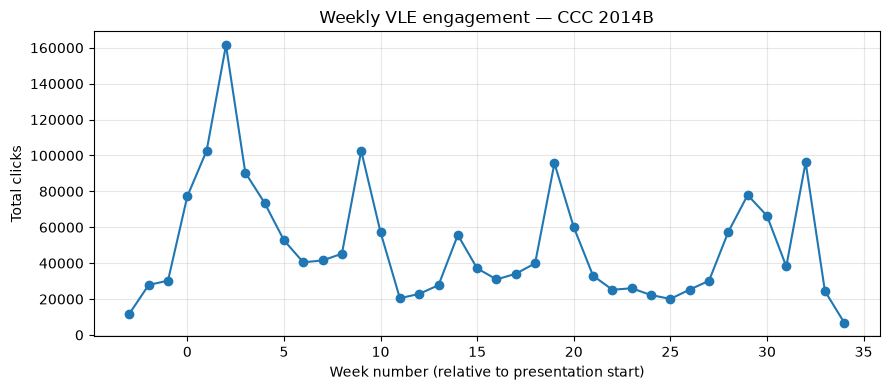

In [5]:
import matplotlib.pyplot as plt

sample = weekly[(weekly.code_module == "CCC") & (weekly.code_presentation == "2014B")]
plt.figure(figsize=(9, 4))
plt.plot(sample.week_number, sample.total_clicks, marker="o")
plt.title("Weekly VLE engagement — CCC 2014B")
plt.xlabel("Week number (relative to presentation start)")
plt.ylabel("Total clicks")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../05_BigData/cc_2014b_weekly_trend.png", dpi=110)
plt.show()

## Reflection

Re-running this notebook from a clean kernel reproduces the exact same row counts
and top-resource rankings reported in the Phase 9 write-up, confirming the
processing is deterministic and not dependent on any manual intermediate step.
The engagement chart for CCC-2014B (the highest-withdrawal presentation
identified in Phase 7) shows a visible decline in engagement partway through
the presentation, consistent with that module's elevated withdrawal rate.